In [2]:
import gymnasium as gym

# Setting up the environment

In [40]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

env = RacetrackEnv(True, soft_reset=True)
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0

results = {
    "crashed" : 0,
    "list_of_steps": []  
}
number_of_steps = 0
while episodes != 100:
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    number_of_steps += 1
    total_reward += reward
    done = terminated or truncated
    # # Uncomment to get a visual of the car traveling
    # clear_output(wait=True)
    # sleep(1)
    # print(env.render())
    if info["crashed"]:
        results["crashed"] += 1
    if done:
        results["list_of_steps"].append(number_of_steps)
        number_of_steps = 0
        if episodes % 10 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print(f"Number of crashes: {results['crashed']}. Average number of steps {sum(results['list_of_steps'])/len(results['list_of_steps'])}")

Finished iteration 0
Finished iteration 10
Finished iteration 20
Finished iteration 30
Finished iteration 40
Finished iteration 50
Finished iteration 60
Finished iteration 70
Finished iteration 80
Finished iteration 90
Number of crashes: 37035. Average number of steps 2301.19


In [42]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

env = RacetrackEnv(True, soft_reset=False)
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0

results = {
    "crashed" : 0,
    "list_of_steps": []  
}
number_of_steps = 0
while episodes != 100:
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    number_of_steps += 1
    total_reward += reward
    done = terminated or truncated
    # # Uncomment to get a visual of the car traveling
    # clear_output(wait=True)
    # sleep(1)
    # print(env.render())
    if info["crashed"]:
        results["crashed"] += 1
    if done:
        results["list_of_steps"].append(number_of_steps)
        number_of_steps = 0
        if episodes % 10 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print(f"Number of crashes: {results['crashed']}. Average number of steps {sum(results['list_of_steps'])/len(results['list_of_steps'])}")

Finished iteration 0
Finished iteration 10
Finished iteration 20
Finished iteration 30
Finished iteration 40
Finished iteration 50
Finished iteration 60
Finished iteration 70
Finished iteration 80
Finished iteration 90
Number of crashes: 100. Average number of steps 6.68


# Solving Markov Decision Problems via Monte Carlo & SARSA

In [95]:
class agent_monte_carlo:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.z_map = {}
        self.q_map = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,trajectory):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        T = len(trajectory)
        y_discount = self.config["discount"]
        
        G = 0
        visited_state_actions = set()
        for t in reversed(range(T - 1)):
            s_t = trajectory[t][:4]
            a_t = trajectory[t][4]
            r_t = trajectory[t + 1][5]
            G = r_t + y_discount*G
            for t_prime in range(t - 1):
                s_t_prime = trajectory[t_prime][:4]
                a_t_prime = trajectory[t_prime][4]
                    
                state_action_pair = (s_t_prime, a_t_prime)
                if state_action_pair not in visited_state_actions:
                    visited_state_actions.add(state_action_pair)
                    if state_action_pair not in self.z_map:
                        self.z_map[state_action_pair] = []
                    self.z_map[state_action_pair].append(G)
                    self.q_map[state_action_pair] = sum(self.z_map[state_action_pair]) / len(self.z_map[state_action_pair])
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        n_actions = 9
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [90]:
# Run this cell to reload the python file!!
import importlib
import racetrack

importlib.reload(racetrack)
from racetrack import RacetrackEnv

In [105]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

agent = agent_monte_carlo({
    "discount": 0.9
})


track_env = RacetrackEnv(soft_reset=True)
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0,
    "list_of_steps": [],
    "rewards": []
}
episodes = 0
epsilon = 0.9

while episodes != 2000:
    if episodes >= 2500:
        epsilon = 0.1
    elif episodes >= 2000:
        epsilon = 0.3
    elif episodes >= 1000:
        epsilon = 0.5
    trajectory = []
    done = False
    action_set = set()
    clear_output(wait=True)
    if episodes % 10 == 0:
        print(f"Episode {episodes}")
    while not done:
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        visits[y, x] += 1
        # sleep(0.01)
        # clear_output(wait=True)
        # print(track_env.render())
        action = agent.pi(state, epsilon)
        action_set.add(action)

        observation, reward, terminated, truncated, info = track_env.step(action)
        crashed = info.get("crashed", None)
        if crashed:
            episode_results["crashed"] += 1

        done = terminated or truncated
        
        # Record the step into the trajectory list
        trajectory.append((x, y, vx, vy, action, reward))
        
    if info["finished"]:
        episode_results["finished"] += 1
        episode_results["list_of_steps"].append(track_env.steps)


    episodes += 1
    track_env.reset()
    agent.update_Q(trajectory)

Episode 1990


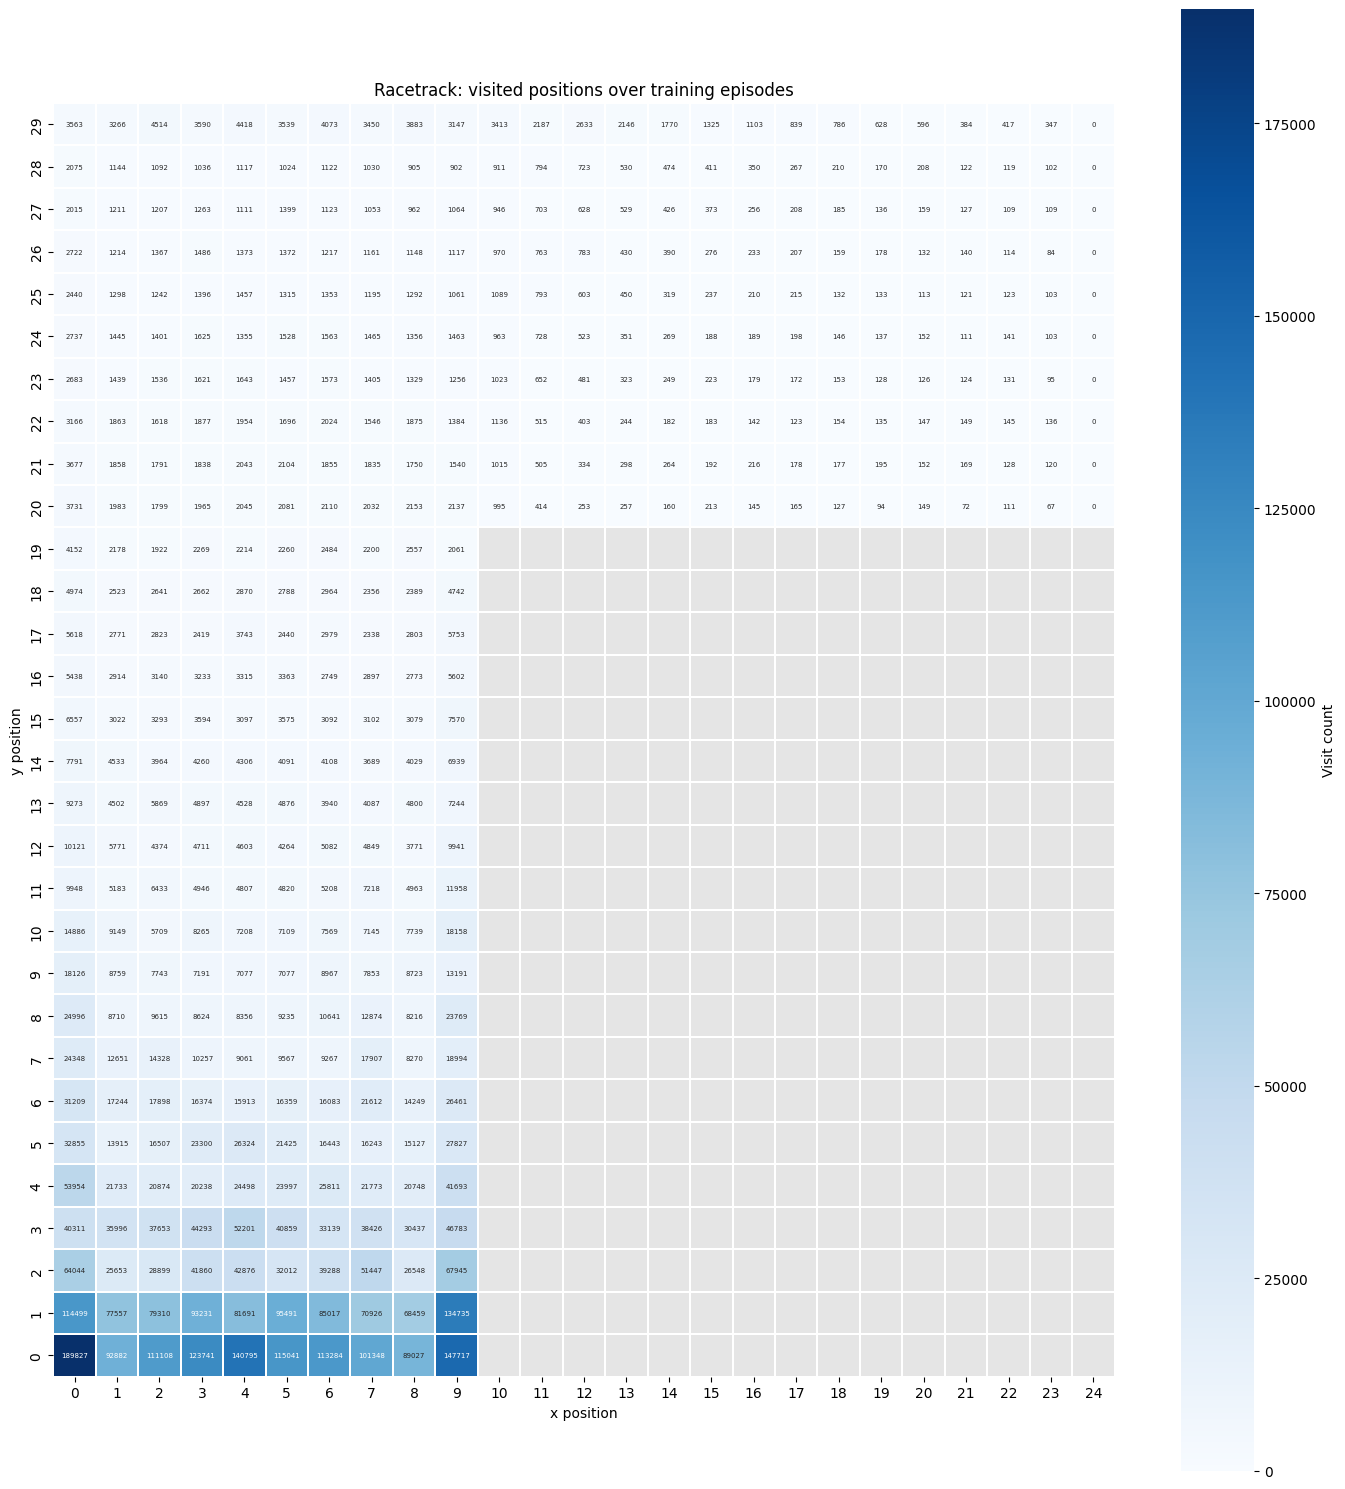

crashed: 760138
average_episode_length: 2350.839


ZeroDivisionError: division by zero

In [106]:
def print_episode_results(results):
    print(f"crashed: {results['crashed']}")
    print(f"average_episode_length: {sum(results['list_of_steps'])/len(results['list_of_steps'])}")
    print(f"average_reward: {sum(results['rewards'])/len(results['rewards'])}")
def plot_heatmap(cells_visited, track_environment):
    mask = ~track_environment.track
    fig, ax = plt.subplots(figsize=(14, 15))
    sns.heatmap(
        cells_visited.astype(float),
        mask=mask,
        cmap="Blues",
        annot=True,
        fmt=".0f",
        annot_kws={"size": 5},
        cbar_kws={"label": "Visit count"},
        linewidths=0.1,
        linecolor="white",
        square=True,
        ax=ax,
    )
    ax.set_facecolor("#e5e5e5")
    ax.invert_yaxis()
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.set_title(f"Racetrack: visited positions over training episodes")
    plt.tight_layout()
    plt.show()
plot_heatmap(visits, track_env)
print_episode_results(episode_results)

In [7]:
import numpy as np

class agent_sarsa:
    '''A class to manage the agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]

    def update_Q(self, trajectory, done):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        state_prime = trajectory[:4]
        action_prime = trajectory[4]
        reward = trajectory[5]
        
        state_action_pair = (self.current_state, self.current_action)
        state_action_prime_pair = (state_prime, action_prime)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]

        q_map_value = self.q_map.get(state_action_pair, 0)
        if done:
            q_map_prime_value = 0
        else:
            state_action_prime_pair = (state_prime, action_prime)
            q_map_prime_value = self.q_map.get(state_action_prime_pair, 0)
        
        self.q_map[state_action_pair] = q_map_value + alpha * (reward + y_discount * q_map_prime_value - q_map_value)
        
        self.current_state = state_prime
        self.current_action = action_prime

    def pi(self, state, epsilon):
        n_actions = self.config.get("n_actions", 9)
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [4]:
import numpy as np
# Had Gemini generate this class based off of my other sarsa class
class agent_expected_sarsa:
    '''A class to manage the Expected SARSA agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying hyperparameters and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]

    def get_probabilities(self, state, epsilon):

        n_actions = self.config.get("n_actions", 9)
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        for ba in best_actions:
            probs[ba] += (1.0 - epsilon) / len(best_actions)
            
        return probs

    def update_Q(self, step_data, epsilon):
        """
        Performs the Expected SARSA step-by-step update.
        step_data is stored as (next_x, next_y, next_vx, next_vy, reward)
        """
        state_prime = step_data[:4]
        reward = step_data[4]
        
        state_action_pair = (self.current_state, self.current_action)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]
        n_actions = self.config.get("n_actions", 9)

        q_map_value = self.q_map.get(state_action_pair, 0.0)
        
        probs = self.get_probabilities(state_prime, epsilon)
        next_action_values = [self.q_map.get((state_prime, a), 0.0) for a in range(n_actions)]
        expected_next_q = np.sum(probs * np.array(next_action_values))
        
        target = reward + y_discount * expected_next_q
        self.q_map[state_action_pair] = q_map_value + alpha * (target - q_map_value)
        
        self.current_state = state_prime

    def pi(self, state, epsilon):
        """
        Selects an action using the epsilon-greedy probability distribution.
        """
        n_actions = self.config.get("n_actions", 9)
        probs = self.get_probabilities(state, epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [111]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


def sarsa_env(sarsa_class, provided_reward, training = True, episodes_max = 2000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            "state": (0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    track_env = RacetrackEnv(provided_reward, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.2
        elif episodes >= episodes_max*0.6:
            epsilon = 0.5
        elif episodes >= episodes_max*0.4:
            epsilon = 0.7
            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        obs, info = track_env.reset()
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        
        action = agent.pi(state, epsilon)
        
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward
            
            next_x, next_y = track_env.pos
            next_vx, next_vy = track_env.vel
            next_state = (next_x, next_y, next_vx, next_vy)
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0  # Dummy action if terminal
                
            step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
            action = next_action
            x, y, vx, vy = next_x, next_y, next_vx, next_vy
    
        # Record metrics at the end of the episode
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env


In [56]:
expected_sarsa_agent, expected_sarsa_visits, expected_sarsa_results, expected_sarsa_track_env = sarsa_env(agent_expected_sarsa, True)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


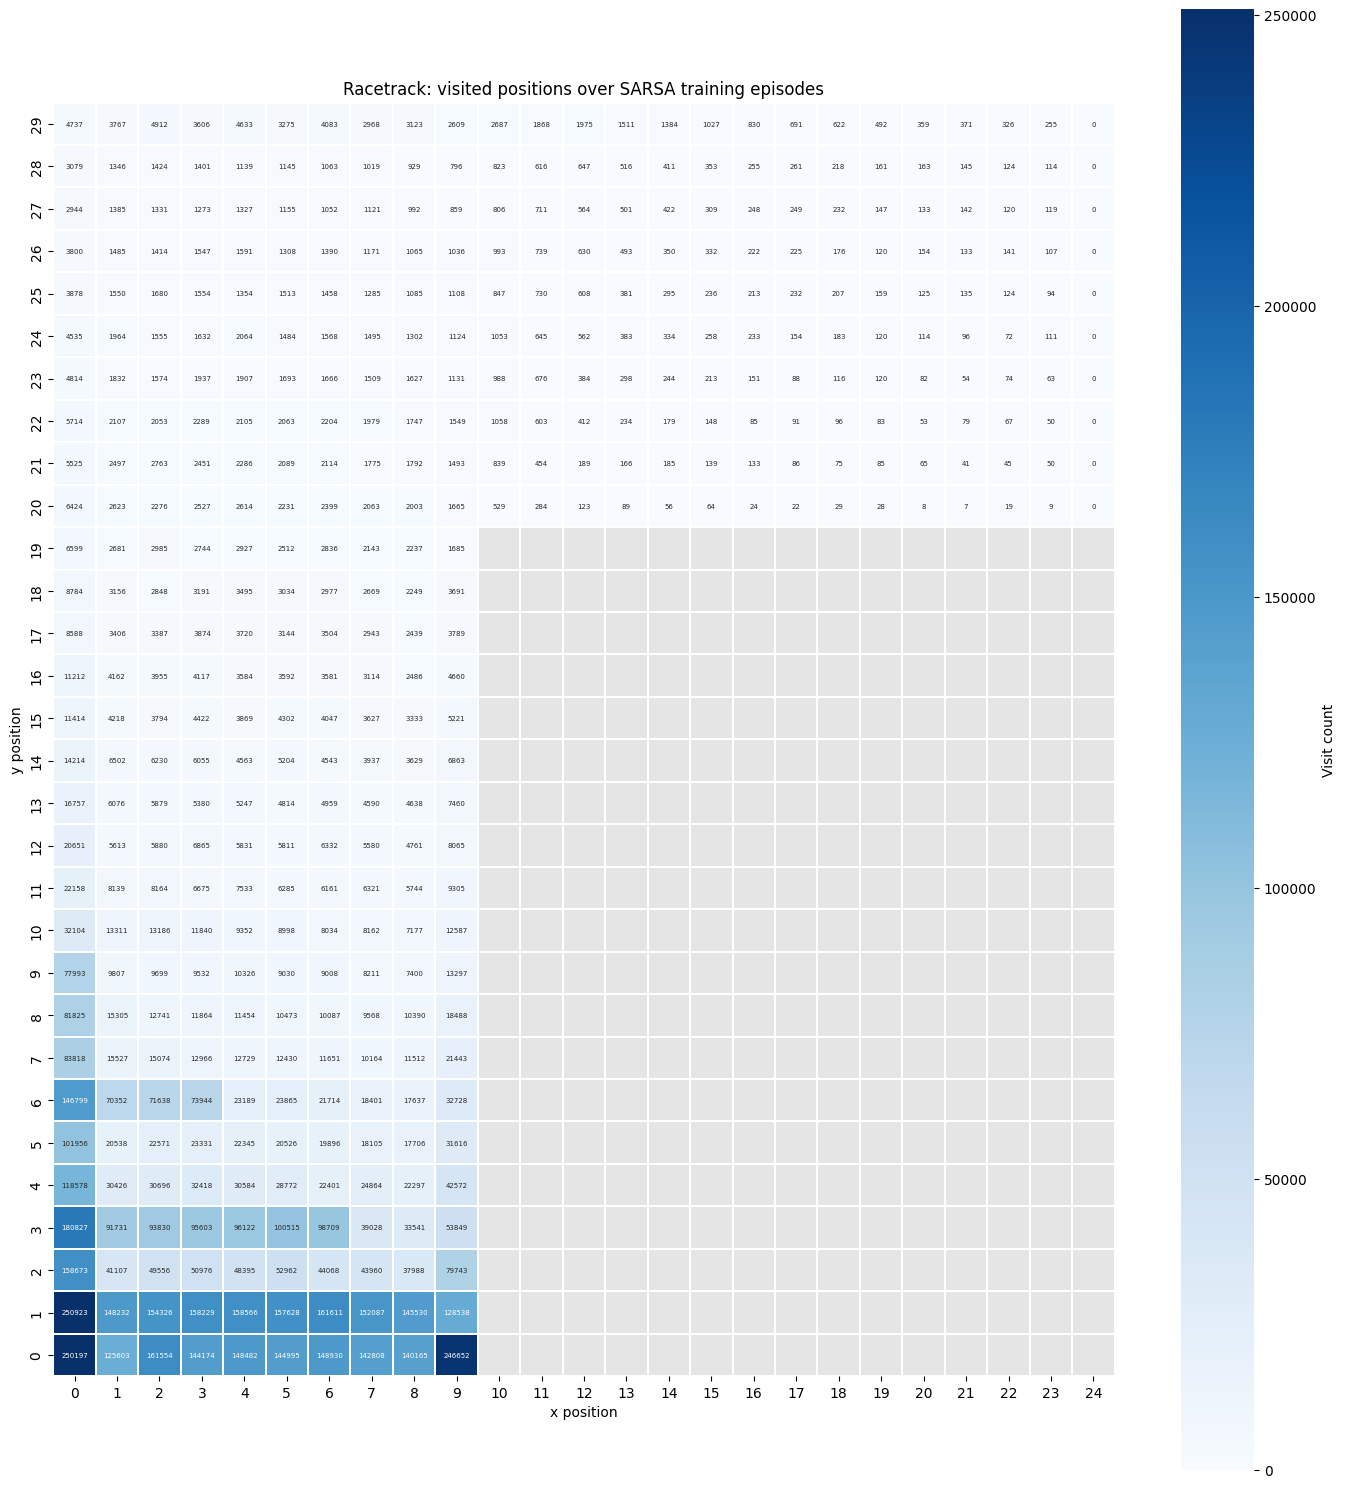

crashed: 1516279
average_episode_length: 3688.2295
average_reward: 100.22358890708198


In [60]:
plot_heatmap(expected_sarsa_visits, expected_sarsa_track_env)
print_episode_results(expected_sarsa_results)

In [58]:
expected_sarsa_my_reward_agent, expected_sarsa_my_reward_visits, expected_sarsa_my_reward_results, expected_sarsa_my_reward_track_env = sarsa_env(agent_expected_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


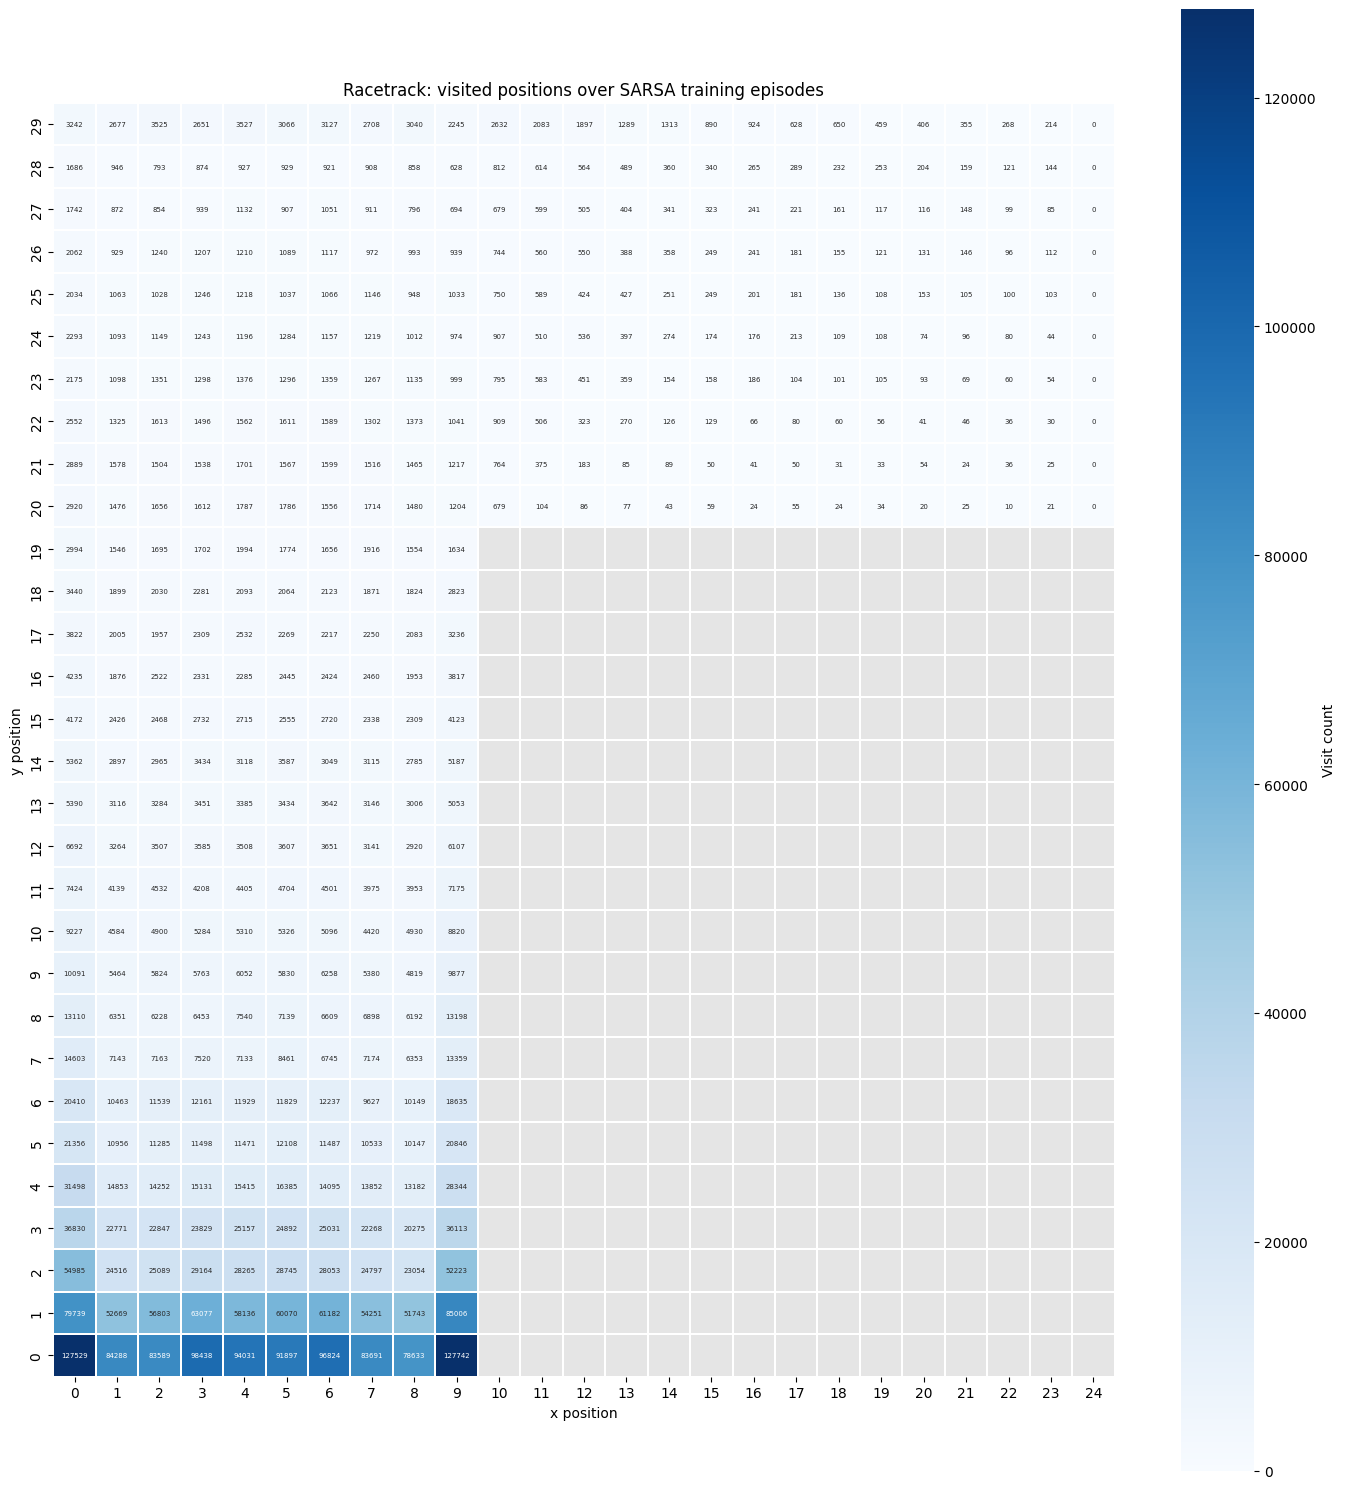

crashed: 536511
average_episode_length: 1683.926
average_reward: 51.70956195151718


In [59]:
plot_heatmap(expected_sarsa_my_reward_visits, expected_sarsa_my_reward_track_env)
print_episode_results(expected_sarsa_my_reward_results)

In [ ]:
sarsa_agent, sarsa_visits, sarsa_results, sarsa_track_env = sarsa_env(agent_sarsa, True, episodes_max = 4500)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Episode 2000
Episode 2100
Episode 2200
Episode 2300
Episode 2400
Episode 2500
Episode 2600
Episode 2700
Episode 2800
Episode 2900
Episode 3000
Episode 3100
Episode 3200


In [ ]:
plot_heatmap(sarsa_visits, sarsa_track_env)
print_episode_results(sarsa_results)

In [ ]:
sarsa_my_reward_agent, sarsa_my_reward_visits, sarsa_my_reward_results, sarsa_my_reward_track_env = sarsa_env(agent_sarsa, False, episodes_max = 4500)

In [ ]:
plot_heatmap(sarsa_my_reward_visits, sarsa_my_reward_track_env)
print_episode_results(sarsa_my_reward_results)

In [81]:
print_episode_results(episode_results)

finished: 34
crashed: 9966
average_episode_length: 25.41176470588235
average_reward: 0.22653107863995264


In [7]:
print_episode_results(episode_results)

finished: 1000
crashed: 0
average_episode_length: 3636.268
average_reward: 193.35713574655284


# Wrecking the learning!
First we just enable the wind speed from the last lab.

In [75]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


def sarsa_with_wind_env(sarsa_class, provided_reward, training = True, episodes_max = 2000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            "state": (0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    track_env = RacetrackEnv(provided_reward, wind_speed=4, wind_chance=0.30, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.1
        elif episodes >= episodes_max*0.6:
            epsilon = 0.3
        elif episodes >= episodes_max*0.3:
            epsilon = 0.5
            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        # Reset environment and get initial state
        obs, info = track_env.reset()
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        
        # 2. Choose the initial action a for the episode
        action = agent.pi(state, epsilon)
        
        # Initialize agent's internal state/action trackers
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward
            
            next_x, next_y = track_env.pos
            next_vx, next_vy = track_env.vel
            next_state = (next_x, next_y, next_vx, next_vy)
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0  # Dummy action if terminal
                
            step_data = (next_x, next_y, next_vx, next_vy, next_action, reward)
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
            action = next_action
            x, y, vx, vy = next_x, next_y, next_vx, next_vy
    
        # Record metrics at the end of the episode
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env


In [76]:
wind_sarsa_my_reward_agent, wind_sarsa_my_reward_visits, wind_sarsa_my_reward_results, wind_sarsa_my_reward_track_env = sarsa_with_wind_env(agent_expected_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


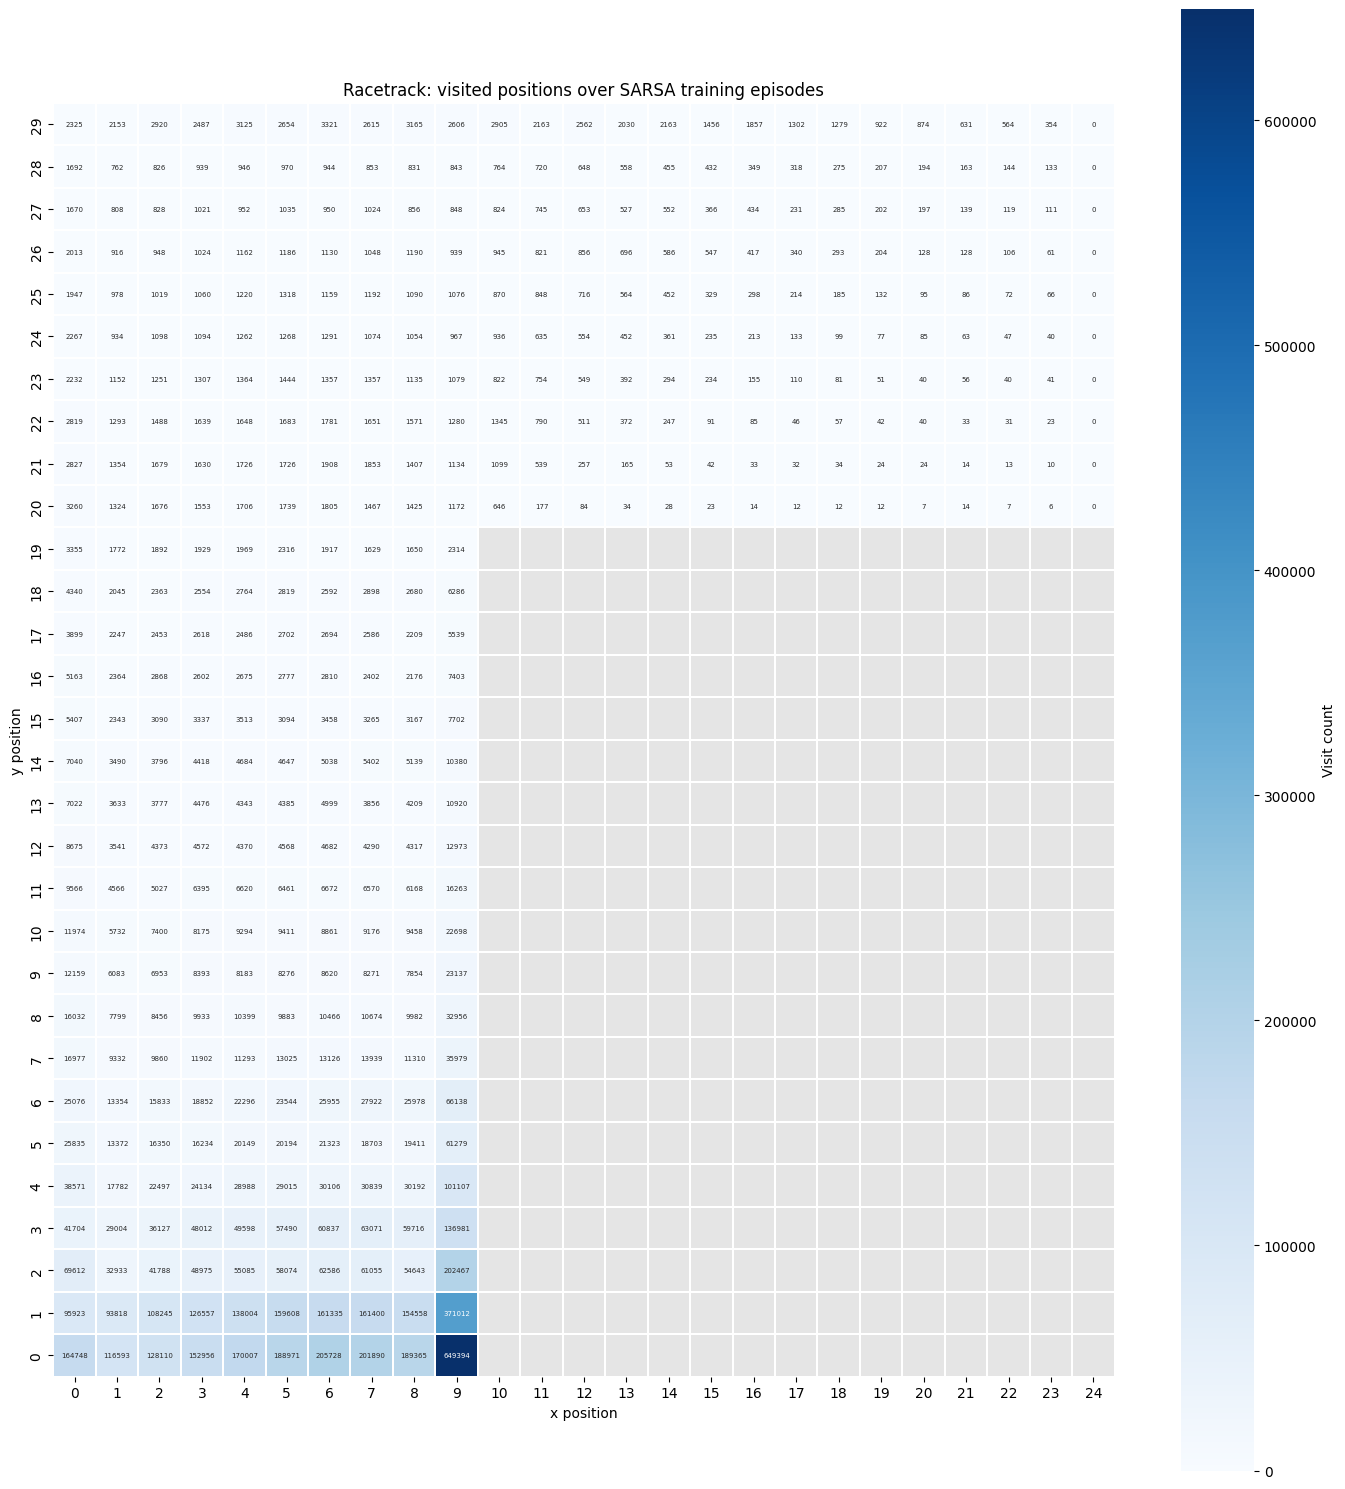

crashed: 1611349
average_episode_length: 3463.615
average_reward: 105.59670635610635


In [77]:
plot_heatmap(wind_sarsa_my_reward_visits, wind_sarsa_my_reward_track_env)
print_episode_results(wind_sarsa_my_reward_results)

We can then add the ability for the environment to share the if the wind would blow in the next iteration.

In [82]:
import numpy as np
class agent_expected_wind_sarsa:
    '''A class to manage the Expected SARSA agent'''
    
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying hyperparameters and initial state
        '''
        self.config = config
        self.q_map = {}
        self.current_state = config["state"]
        self.current_action = config["action"]

    def get_probabilities(self, state, epsilon):

        n_actions = self.config.get("n_actions", 9)
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        for ba in best_actions:
            probs[ba] += (1.0 - epsilon) / len(best_actions)
            
        return probs

    def update_Q(self, step_data, epsilon):
        """
        Performs the Expected SARSA step-by-step update.
        step_data is stored as (next_x, next_y, next_vx, next_vy, wind_incoming, reward)
        """
        state_prime = step_data[:5]
        reward = step_data[5]
        
        state_action_pair = (self.current_state, self.current_action)
        
        alpha = self.config["alpha"]
        y_discount = self.config["discount"]
        n_actions = self.config.get("n_actions", 9)

        q_map_value = self.q_map.get(state_action_pair, 0.0)
        
        probs = self.get_probabilities(state_prime, epsilon)
        next_action_values = [self.q_map.get((state_prime, a), 0.0) for a in range(n_actions)]
        expected_next_q = np.sum(probs * np.array(next_action_values))
        
        # 3. Expected SARSA update rule[cite: 8]
        target = reward + y_discount * expected_next_q
        self.q_map[state_action_pair] = q_map_value + alpha * (target - q_map_value)
        
        # 4. Shift current state forward
        self.current_state = state_prime

    def pi(self, state, epsilon):
        """
        Selects an action using the epsilon-greedy probability distribution.
        """
        n_actions = self.config.get("n_actions", 9)
        probs = self.get_probabilities(state, epsilon)
        
        # Sample and return an action based on the probabilities
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

In [81]:
def sarsa_with_wind_env(sarsa_class, provided_reward, training = True, episodes_max = 2000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            # Updated initial state to include wind status (e.g., 5 elements)
            "state": (0, 0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    
    # Pass provided_reward into your RacetrackEnv constructor
    track_env = RacetrackEnv(provided_reward, wind_speed=4, wind_chance=0.30, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.8 * int(training)
    
    while episodes != episodes_max:
        if episodes >= episodes_max*0.8:
            epsilon = 0.1
        elif episodes >= episodes_max*0.6:
            epsilon = 0.3
        elif episodes >= episodes_max*0.3:
            epsilon = 0.5
            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        # 1. Reset environment and unpack all 5 observation features: (x, y, vx, vy, wind_approaching)
        obs, info = track_env.reset()
        x, y, vx, vy, wind_app = obs
        state = (x, y, vx, vy, int(wind_app))
        
        # 2. Choose the initial action for the episode
        action = agent.pi(state, epsilon)
        
        # Initialize agent's internal state/action trackers
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward

            # We now use the wind_incoming flag to help the agent adjust according ly
            next_x, next_y, next_vx, next_vy, wind_incoming = observation
            next_state = (next_x, next_y, next_vx, next_vy, int(next_wind_app))
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0  # Dummy action if terminal
                
            step_data = (next_x, next_y, next_vx, next_vy, next_wind_app, next_action, reward)
            
            if training:
                agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
                
            action = next_action
            x, y, vx, vy, wind_app = next_x, next_y, next_vx, next_vy, next_wind_app
        
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env

In [92]:
wind_sarsa_new_context_agent, wind_sarsa_new_context_visits, wind_sarsa_new_context_results, wind_sarsa_new_context_track_env = sarsa_with_wind_env(agent_expected_wind_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


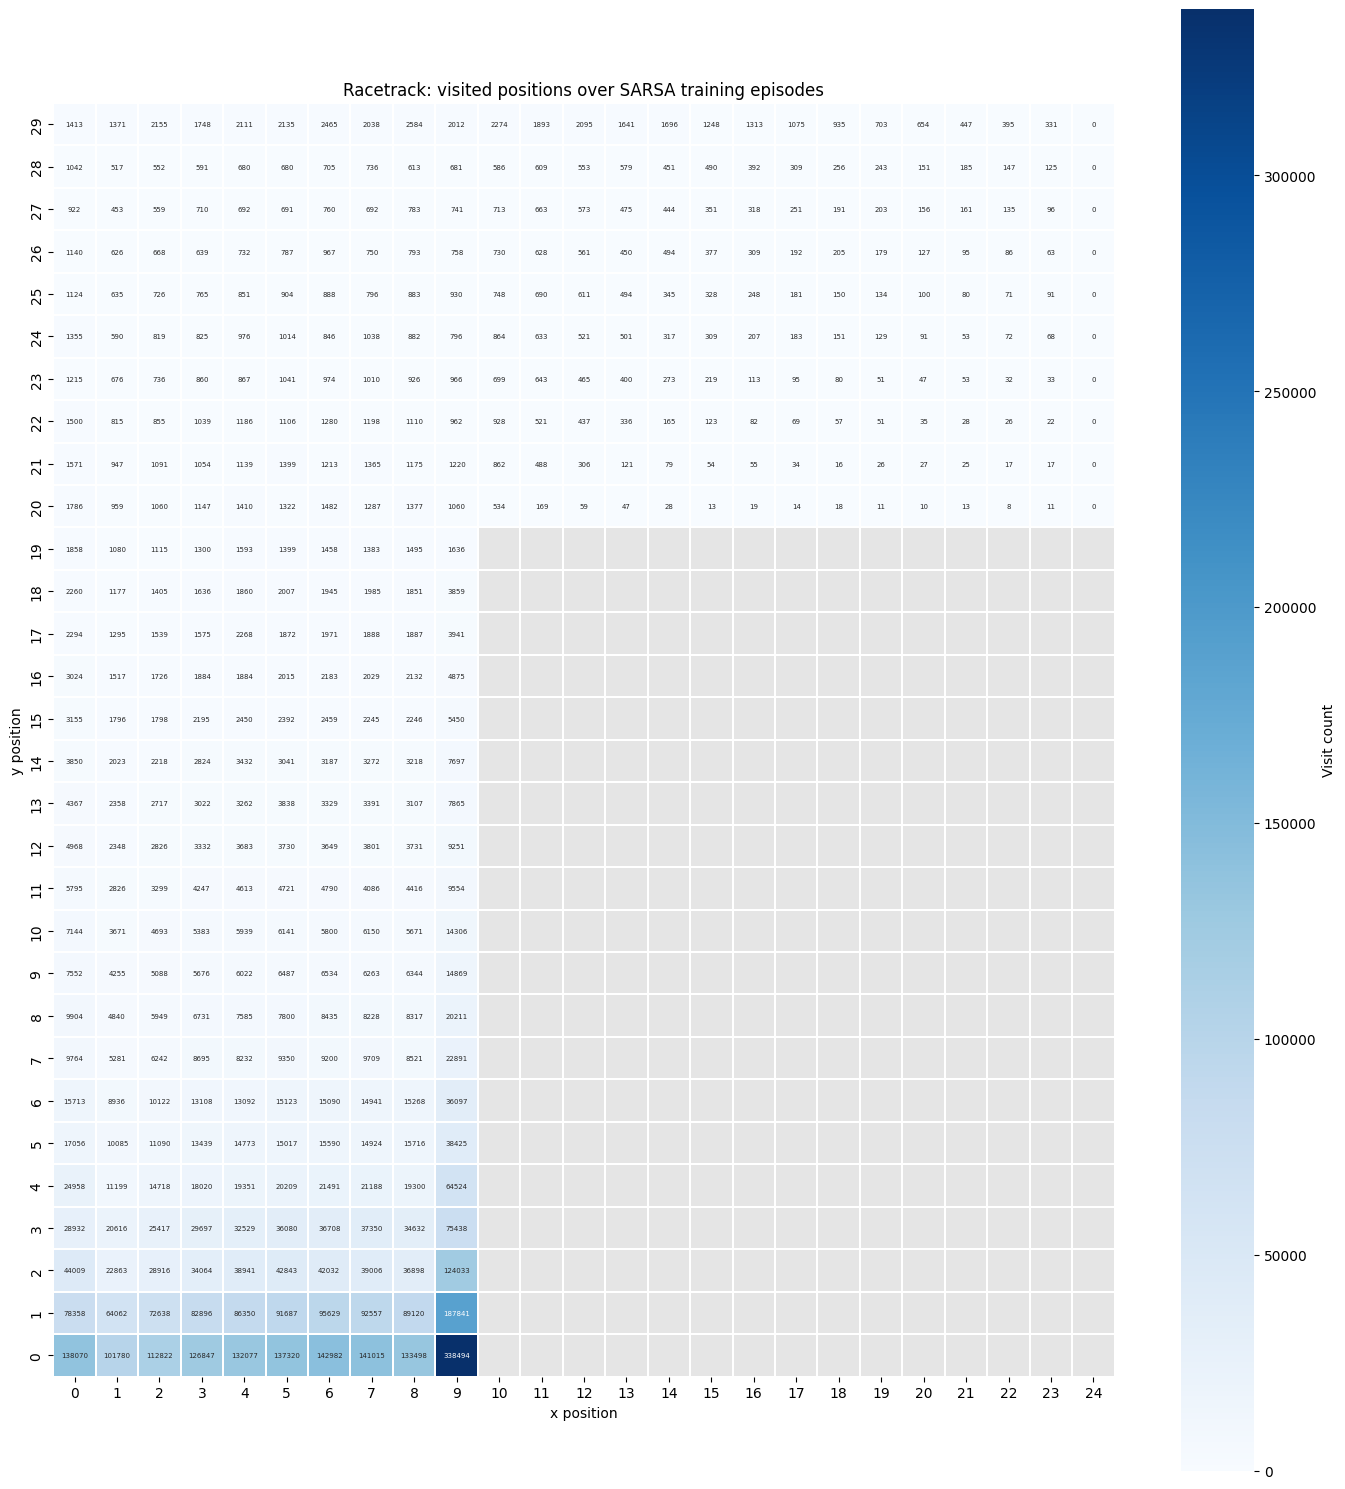

crashed: 911243
average_episode_length: 2277.3555
average_reward: -1167.3675


In [93]:
plot_heatmap(wind_sarsa_new_context_visits, wind_sarsa_new_context_track_env)
print_episode_results(wind_sarsa_new_context_results)

In [100]:
def sarsa_with_no_decay_env(sarsa_class, provided_reward, episodes_max = 2000, agent = None):
    if agent is None:
        assert sarsa_class is not None
        agent = sarsa_class({
            "discount": 0.9,
            # Updated initial state to include wind status (e.g., 5 elements)
            "state": (0, 0, 0, 0, 0),
            "action": 0,
            "alpha": 0.1,
            "n_actions": 9
        })
    
    # Pass provided_reward into your RacetrackEnv constructor
    track_env = RacetrackEnv(provided_reward, soft_reset=training)
    visits = np.zeros((track_env.height, track_env.width), dtype=int)
    
    episode_results = {
        "crashed": 0,
        "list_of_steps": [],
        "rewards": []
    }
    episodes = 0
    epsilon = 0.9
    
    while episodes != episodes_max:            
        if episodes % 100 == 0:
            print(f"Episode {episodes}")
            
        obs, info = track_env.reset()
        x, y, vx, vy, wind_app = obs
        state = (x, y, vx, vy, int(wind_app))
        
        action = agent.pi(state, epsilon)
        
        agent.current_state = state
        agent.current_action = action
        
        done = False
        total_episode_reward = 0
        
        while not done:
            visits[y, x] += 1
            
            observation, reward, terminated, truncated, info = track_env.step(action)
            done = terminated or truncated
            total_episode_reward += reward

            # We now use the wind_incoming flag to help the agent adjust according ly
            next_x, next_y, next_vx, next_vy, wind_incoming = observation
            next_state = (next_x, next_y, next_vx, next_vy, int(wind_incoming))
            
            if not done:
                next_action = agent.pi(next_state, epsilon)
            else:
                next_action = 0
                
            step_data = (next_x, next_y, next_vx, next_vy, wind_incoming, next_action, reward)
            
            
            agent.update_Q(step_data, done)

            if info.get("crashed", False):
                episode_results["crashed"] += 1            
                state = next_state
                
            action = next_action
            x, y, vx, vy, wind_app = next_x, next_y, next_vx, next_vy, wind_incoming
        
        if info.get("finished", False):
            episode_results["list_of_steps"].append(track_env.steps)
            
        episode_results["rewards"].append(total_episode_reward)
        episodes += 1
    
    print("Training finished!")
    return agent, visits, episode_results, track_env

In [103]:
no_decay_sarsa_agent, no_decay_sarsa_visits, no_decay_sarsa_results, no_decay_sarsa_track_env = sarsa_with_wind_env(agent_expected_wind_sarsa, False)

Episode 0
Episode 100
Episode 200
Episode 300
Episode 400
Episode 500
Episode 600
Episode 700
Episode 800
Episode 900
Episode 1000
Episode 1100
Episode 1200
Episode 1300
Episode 1400
Episode 1500
Episode 1600
Episode 1700
Episode 1800
Episode 1900
Training finished!


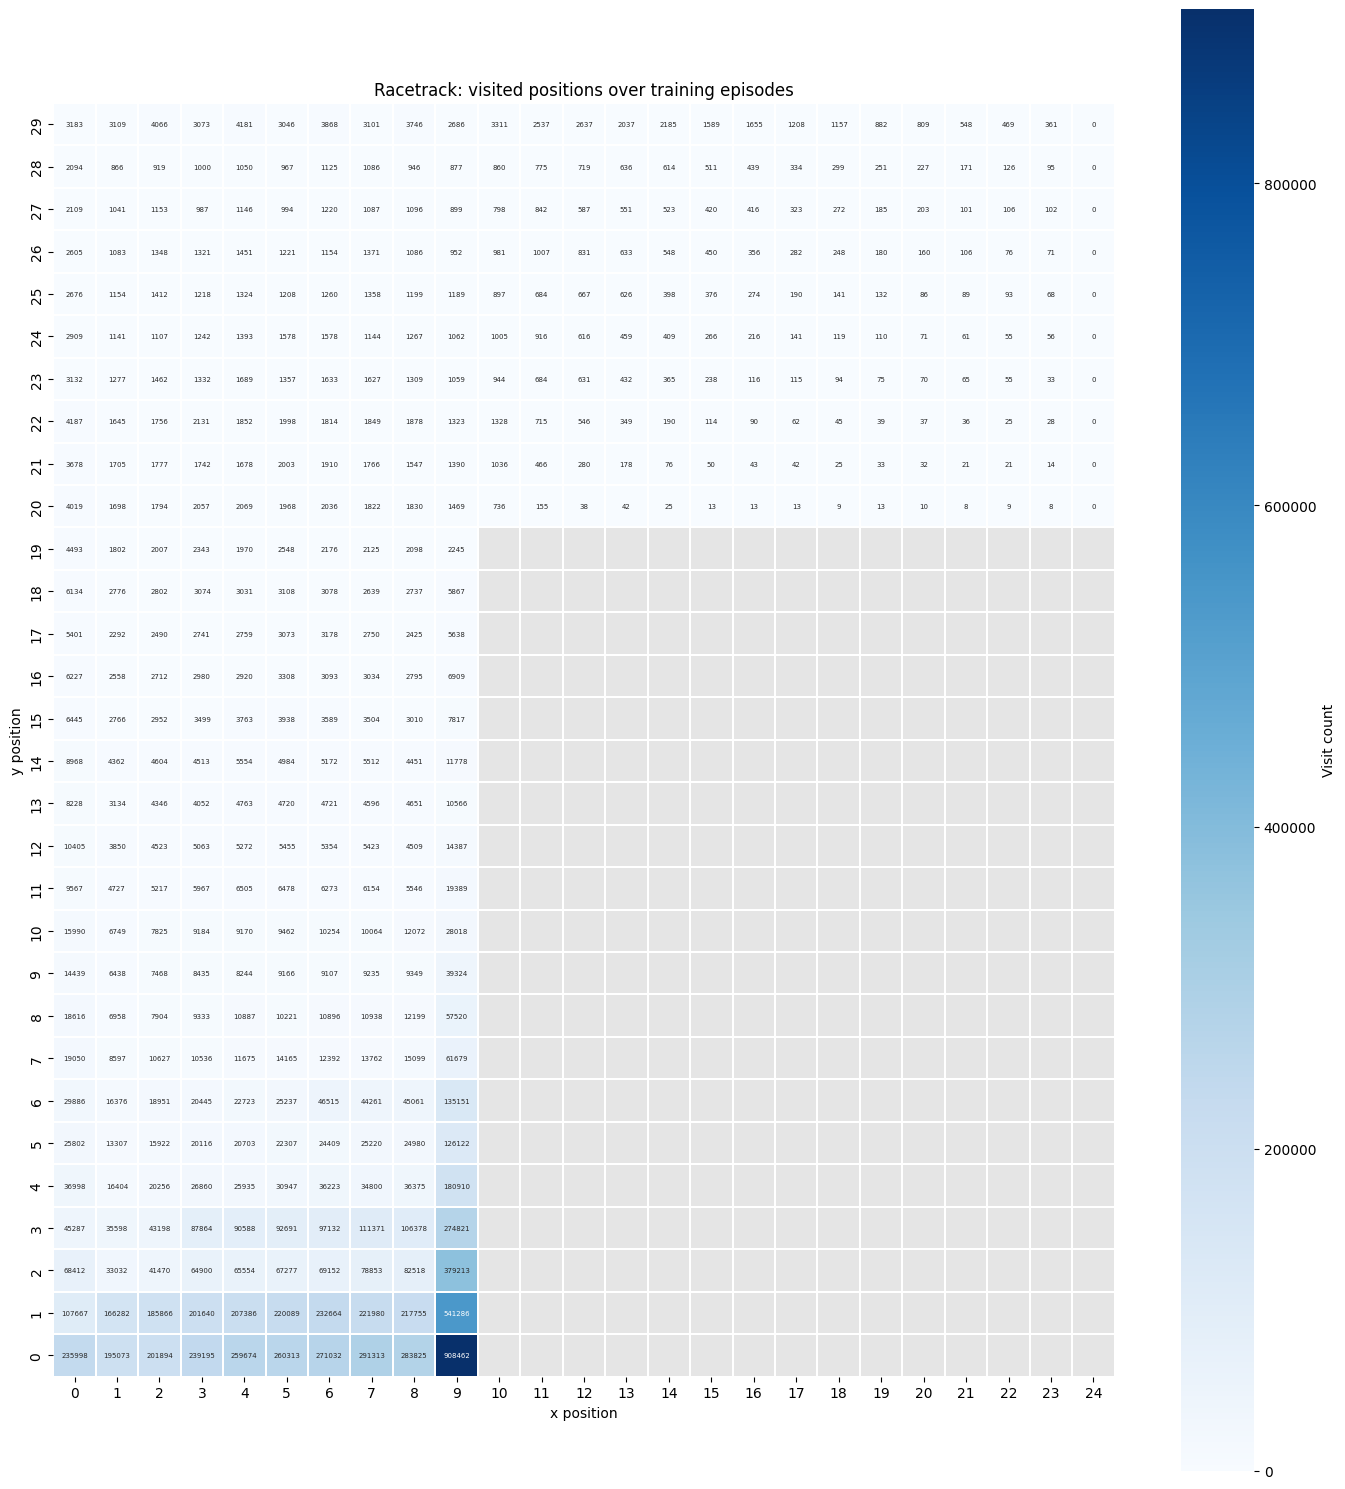

crashed: 2448307
average_episode_length: 4892.1305
average_reward: -2456.6924000000004


In [104]:
plot_heatmap(no_decay_sarsa_visits, no_decay_sarsa_track_env)
print_episode_results(no_decay_sarsa_results)